# QA Fine-tuning & Experiments - LAB 10

Nội dung: baseline, fine-tune DistilBERT cho extractive QA (Experiment 2), context length (Experiment 1), EM vs F1 (Experiment 3), question/context matching (Experiment 4), answer length (Experiment 5), kiểm tra Prediction 3 - 4, thống kê lỗi cho error_analysis.md.

Toàn bộ logic (tokenize, alignment, training loop, post-processing, metric, baseline) nằm trong qa_model.py. Việc fine-tune trên CPU mất khoảng 1 giờ mỗi cấu hình nên hàm run_experiment lưu kết quả vào outputs/lenXXX/. Notebook chỉ train lại khi chưa có kết quả.

In [1]:
import os, json, time, platform, collections, random, re
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import qa_model as qm

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
qm.set_seed(qm.SEED)
train_ds, val_ds, test_ds = qm.load_splits()
tok = qm.AutoTokenizer.from_pretrained(qm.MODEL_NAME)
print(len(train_ds), len(val_ds), len(test_ds))

3000 300 1000


## 0. Reproducibility

In [2]:
m384 = json.load(open("outputs/len384/metrics.json")) if os.path.exists("outputs/len384/metrics.json") else None
repro = {
    "Model": "distilbert-base-uncased + linear QA head (AutoModelForQuestionAnswering)",
    "Tokenizer": "distilbert-base-uncased (WordPiece, fast tokenizer)",
    "Dataset": "SQuAD v1.1 (rajpurkar/squad)",
    "Train split": f"{len(train_ds)} câu hỏi ngẫu nhiên từ SQuAD train (shuffle seed 42)",
    "Validation split": f"{len(val_ds)} câu hỏi từ SQuAD validation (index 1000-1299 sau shuffle), dùng cho validation loss",
    "Test split": f"{len(test_ds)} câu hỏi từ SQuAD validation (index 0-999 sau shuffle), dùng cho EM/F1",
    "Max sequence length": "384 (Experiment 1: 128 / 256 / 384)",
    "Stride": "128 (Experiment 1: 42 / 85 / 128, giữ overlap = 1/3 max_length)",
    "Batch size": 16,
    "Learning rate": "5e-5, linear decay, warmup 10%, weight decay 0.01, grad clip 1.0",
    "Epochs": 2,
    "Optimizer": "AdamW",
    "Random seed": 42,
    "Hardware": f"CPU {platform.processor()} ({torch.get_num_threads()} threads), không GPU, torch {torch.__version__}",
    "Training time": f"{m384['train_time_s']/60:.1f} phút (max_length 384)" if m384 else "chưa train",
}
for k, v in repro.items():
    print(f"{k}: {v}")

Model: distilbert-base-uncased + linear QA head (AutoModelForQuestionAnswering)
Tokenizer: distilbert-base-uncased (WordPiece, fast tokenizer)
Dataset: SQuAD v1.1 (rajpurkar/squad)
Train split: 3000 câu hỏi ngẫu nhiên từ SQuAD train (shuffle seed 42)
Validation split: 300 câu hỏi từ SQuAD validation (index 1000-1299 sau shuffle), dùng cho validation loss
Test split: 1000 câu hỏi từ SQuAD validation (index 0-999 sau shuffle), dùng cho EM/F1
Max sequence length: 384 (Experiment 1: 128 / 256 / 384)
Stride: 128 (Experiment 1: 42 / 85 / 128, giữ overlap = 1/3 max_length)
Batch size: 16
Learning rate: 5e-5, linear decay, warmup 10%, weight decay 0.01, grad clip 1.0
Epochs: 2
Optimizer: AdamW
Random seed: 42
Hardware: CPU Intel64 Family 6 Model 186 Stepping 2, GenuineIntel (14 threads), không GPU, torch 2.12.0+cpu
Training time: 70.5 phút (max_length 384)


## 1. Dữ liệu

In [3]:
def n_tokens(q, c):
    return len(tok(q, c)["input_ids"])

test_len = np.array([n_tokens(e["question"], e["context"]) for e in test_ds])
print("số token (question + context) trên test: mean %.0f, median %.0f, max %d" % (test_len.mean(), np.median(test_len), test_len.max()))
for L in [128, 256, 384]:
    print(f"  > {L} token: {(test_len > L).mean()*100:.1f}% test example")
ex = train_ds[0]
print(ex["question"], "->", ex["answers"])

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (524 > 512). Running this sequence through the model will result in indexing errors


số token (question + context) trên test: mean 178, median 166, max 577
  > 128 token: 80.0% test example
  > 256 token: 11.6% test example
  > 384 token: 1.8% test example
What percentage of Egyptians polled support death penalty for those leaving Islam? -> {'text': ['84%'], 'answer_start': [468]}


## 2. Baseline: keyword overlap

Question -> keyword overlap -> candidate sentence -> candidate span (qm.baseline_predict):

1. bỏ stopword, chọn câu trong context có nhiều từ trùng với question nhất;
2. trong câu đó, candidate span = các đoạn liên tiếp không chứa từ của question / stopword / dấu câu;
3. chọn candidate gần các từ trùng nhất, tối đa 5 từ.

In [4]:
base_pred = {e["id"]: qm.baseline_predict(e["question"], e["context"]) for e in test_ds}
base_res = qm.evaluate(test_ds, base_pred)
print(f"Baseline: EM = {base_res['EM']:.2f}, F1 = {base_res['F1']:.2f}")
for e in list(test_ds)[:5]:
    print(f"Q: {e['question']}\n  gold: {e['answers']['text'][0]!r} | baseline: {base_pred[e['id']]!r}")

Baseline: EM = 11.20, F1 = 20.56
Q: In what year did Massachusetts first require children to be educated in schools?
  gold: '1852' | baseline: 'compulsory education'
Q: When were stromules discovered?
  gold: '1962' | baseline: 'very rare'
Q: Which artist who had a major influence on the Gothic Revival is represented in the V&A's British galleries?
  gold: 'Horace Walpole' | baseline: 'also'
Q: In 1890, who did the university decide to team up with?
  gold: 'several regional colleges and universities' | baseline: 'Butler'
Q: Who got a touchdown making the score 10-7?
  gold: 'Jonathan Stewart' | baseline: '1-yard'


## 3. Experiment 2 - Fine-tune pretrained Transformer (max_length 384)

In [5]:
def run_or_load(L, S, save_model=False):
    path = f"outputs/len{L}"
    if not os.path.exists(f"{path}/metrics.json"):
        qm.run_experiment(path, max_length=L, stride=S, save_model=save_model)
    hist = json.load(open(f"{path}/history.json"))
    # bỏ điểm log cuối nếu chỉ là trung bình của vài bước lẻ (nhiễu)
    st = hist["step"]
    if len(st) > 2 and st[-1] - st[-2] < (st[1] - st[0]) / 2:
        for k in ["step", "epoch", "train_loss", "val_loss"]:
            hist[k] = hist[k][:-1]
    metrics = json.load(open(f"{path}/metrics.json"))
    preds = json.load(open(f"{path}/test_predictions.json", encoding="utf-8"))
    return hist, metrics, preds

hist384, met384, pred384 = run_or_load(384, 128, save_model=True)
h = pd.DataFrame({k: hist384[k] for k in ["step", "epoch", "train_loss", "val_loss"]})
print(h.round(4).to_string(index=False))
print({k: (round(v, 2) if k != "lr" else v) if isinstance(v, float) else v for k, v in met384.items()})

 step  epoch  train_loss  val_loss
   47 0.2474      5.0632    4.0453
   94 0.4947      3.8304    3.6239
  141 0.7421      3.3984    2.7654
  188 0.9895      2.7482    2.4133
  235 1.2368      2.1881    2.1837
  282 1.4842      1.9036    2.0826
  329 1.7316      1.8599    2.0557
  376 1.9789      1.7575    2.0152
{'max_length': 384, 'stride': 128, 'epochs': 2, 'lr': 5e-05, 'batch_size': 16, 'seed': 42, 'n_train': 3000, 'n_train_features': 3030, 'n_test': 1000, 'EM': 46.7, 'F1': 57.5, 'train_time_s': 4229.04, 'test_infer_time_s': 98.81}


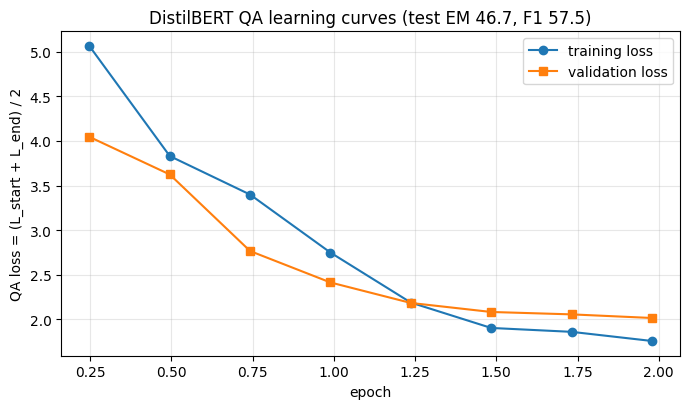

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(h["epoch"], h["train_loss"], "o-", label="training loss")
ax.plot(h["epoch"], h["val_loss"], "s-", label="validation loss")
ax.set_xlabel("epoch")
ax.set_ylabel("QA loss = (L_start + L_end) / 2")
ax.set_title(f"DistilBERT QA learning curves (test EM {met384['EM']:.1f}, F1 {met384['F1']:.1f})")
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

## 4. Experiment 3 - EM vs F1

In [7]:
ft_text = {k: v["text"] for k, v in pred384.items()}
ft_res = qm.evaluate(test_ds, ft_text)
tbl3 = pd.DataFrame([
    {"Model": "Baseline (keyword overlap)", "EM": base_res["EM"], "F1": base_res["F1"]},
    {"Model": "Fine-tuned DistilBERT", "EM": ft_res["EM"], "F1": ft_res["F1"]},
]).round(2)
print(tbl3.to_string(index=False))

                     Model   EM    F1
Baseline (keyword overlap) 11.2 20.56
     Fine-tuned DistilBERT 46.7 57.50


In [8]:
rows = []
for e, em, f1 in zip(test_ds, ft_res["em_list"], ft_res["f1_list"]):
    if em == 0 and f1 > 0:
        rows.append({"id": e["id"], "question": e["question"], "gold": " | ".join(sorted(set(e["answers"]["text"]))),
                     "prediction": ft_text[e["id"]], "F1": round(f1, 3)})
emf1 = pd.DataFrame(rows)
print("Số example EM = 0 nhưng F1 > 0:", len(emf1), "/", len(test_ds))
print(emf1.sample(10, random_state=1).to_string(index=False))

Số example EM = 0 nhưng F1 > 0: 236 / 1000
                      id                                                                               question                                                                                                      gold                                                                                 prediction    F1
57281bbc2ca10214002d9dfc                                                  When was a Doctor Who Prom performed?                                                                                              27 July 2008                                                      27 July 2008 in the Royal Albert Hall 0.600
5727f2714b864d1900164076    What contributed to the decreased inequality between trained and untrained workers?                                                                 decrease in wages | period of compression                                                                                compression 0.500
571ccc00dd7a

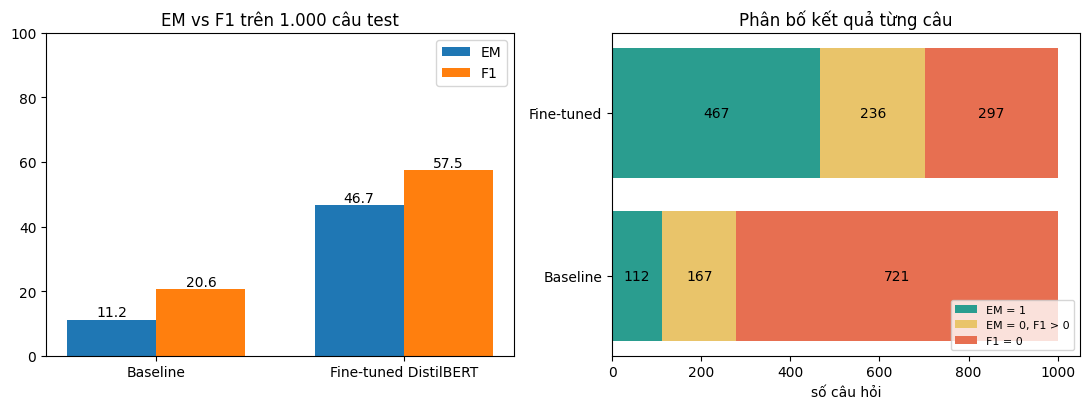

In [9]:
def bucket(em, f1):
    return np.where(np.array(em) == 1, "EM = 1", np.where(np.array(f1) > 0, "EM = 0, F1 > 0", "F1 = 0"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(2)
axes[0].bar(x - .18, [base_res["EM"], ft_res["EM"]], .36, label="EM")
axes[0].bar(x + .18, [base_res["F1"], ft_res["F1"]], .36, label="F1")
for i, (a, b) in enumerate([(base_res["EM"], base_res["F1"]), (ft_res["EM"], ft_res["F1"])]):
    axes[0].text(i - .18, a + 1, f"{a:.1f}", ha="center")
    axes[0].text(i + .18, b + 1, f"{b:.1f}", ha="center")
axes[0].set_xticks(x, ["Baseline", "Fine-tuned DistilBERT"])
axes[0].set_ylim(0, 100)
axes[0].set_title("EM vs F1 trên 1.000 câu test")
axes[0].legend()
cats = ["EM = 1", "EM = 0, F1 > 0", "F1 = 0"]
for i, (name, r) in enumerate([("Baseline", base_res), ("Fine-tuned", ft_res)]):
    b = bucket(r["em_list"], r["f1_list"])
    left = 0
    for c, col in zip(cats, ["#2a9d8f", "#e9c46a", "#e76f51"]):
        n = (b == c).sum()
        axes[1].barh(i, n, left=left, color=col, label=c if i == 0 else None)
        axes[1].text(left + n / 2, i, str(n), ha="center", va="center")
        left += n
axes[1].set_yticks([0, 1], ["Baseline", "Fine-tuned"])
axes[1].set_xlabel("số câu hỏi")
axes[1].set_title("Phân bố kết quả từng câu")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("em_f1_analysis.png", dpi=150)
plt.show()

## 5. Experiment 1 - Context length

In [10]:
exp1 = {}
for L, S in [(128, 42), (256, 85), (384, 128)]:
    exp1[L] = run_or_load(L, S, save_model=(L == 384))
tbl1 = pd.DataFrame([{"Max length": L, "Stride": m["stride"], "Train features": m["n_train_features"],
                      "EM": m["EM"], "F1": m["F1"], "Training time (min)": m["train_time_s"] / 60,
                      "Final val loss": h_["val_loss"][-1]}
                     for L, (h_, m, p) in exp1.items()]).round(2)
print(tbl1.to_string(index=False))

 Max length  Stride  Train features   EM    F1  Training time (min)  Final val loss
        128      42            6425 46.4 57.64                60.33            1.41
        256      85            3330 45.2 56.52                52.90            2.05
        384     128            3030 46.7 57.50                70.48            2.02


In [11]:
# F1 theo độ dài input của test example
groups = pd.cut(test_len, [0, 128, 256, 10000], labels=["<=128", "129-256", ">256"])
rows = []
for L, (_, _, p) in exp1.items():
    r = qm.evaluate(test_ds, {k: v["text"] for k, v in p.items()})
    df = pd.DataFrame({"group": groups, "EM": r["em_list"], "F1": r["f1_list"]})
    g = df.groupby("group", observed=False)[["EM", "F1"]].mean() * 100
    for grp, row in g.iterrows():
        rows.append({"max_length": L, "input length": grp, "n": int((groups == grp).sum()), "EM": row.EM, "F1": row.F1})
print(pd.DataFrame(rows).pivot(index="input length", columns="max_length", values="F1").round(1))

max_length     128   256   384
input length                  
129-256       58.9  59.2  60.2
<=128         54.4  52.8  54.9
>256          55.7  47.3  46.3


## 6. Experiment 4 - Question/Context matching (lexical overlap)

In [12]:
def content_words(text):
    return {qm._content(w) for w in qm._WORD_RE.findall(text)} - {None}

def answer_sentence(e):
    a = e["answers"]["answer_start"][0]
    for s, t in qm._sentences(e["context"]):
        if s <= a < t:
            return e["context"][s:t]
    return e["context"]

overlap = np.array([len(content_words(e["question"]) & content_words(answer_sentence(e))) / max(1, len(content_words(e["question"])))
                    for e in test_ds])
lo_t, hi_t = np.quantile(overlap, [1 / 3, 2 / 3])
grp = np.where(overlap >= hi_t, "high overlap", np.where(overlap <= lo_t, "low overlap", "medium"))
rows = []
for name, r in [("Baseline", base_res), ("Fine-tuned", ft_res)]:
    for g in ["high overlap", "medium", "low overlap"]:
        m = grp == g
        rows.append({"Model": name, "Group": g, "n": m.sum(), "EM": np.mean(np.array(r["em_list"])[m]) * 100,
                     "F1": np.mean(np.array(r["f1_list"])[m]) * 100})
tbl4 = pd.DataFrame(rows).round(2)
print(f"overlap = |content words(question) ∩ content words(câu chứa answer)| / |content words(question)|; low <= {lo_t:.2f}, high >= {hi_t:.2f}")
print(tbl4.to_string(index=False))

overlap = |content words(question) ∩ content words(câu chứa answer)| / |content words(question)|; low <= 0.43, high >= 0.67
     Model        Group   n    EM    F1
  Baseline high overlap 388 15.46 28.22
  Baseline       medium 264 12.50 21.33
  Baseline  low overlap 348  5.46 11.43
Fine-tuned high overlap 388 53.87 65.53
Fine-tuned       medium 264 51.89 61.14
Fine-tuned  low overlap 348 34.77 45.79


In [13]:
# Cặp câu hỏi thủ công: cùng answer, lexical overlap cao vs paraphrase
model384 = qm.AutoModelForQuestionAnswering.from_pretrained("outputs/len384/model")
tok384 = qm.AutoTokenizer.from_pretrained("outputs/len384/model")
pairs = [
    ("What city is the capital of France?", "Paris is the capital of France."),
    ("Where is the French government based?", "The French government is based in Paris."),
    ("Where is the French government based?", "Paris is the capital of France."),
    ("Who wrote Hamlet?", "Hamlet was written by William Shakespeare around 1600."),
    ("Which playwright is the author of the tragedy about the Danish prince?", "Hamlet was written by William Shakespeare around 1600."),
    ("When did the war end?", "The war ended in 1945 after six years of fighting."),
    ("In what year did the fighting stop?", "The war ended in 1945 after six years of fighting."),
]
for q, c in pairs:
    p = qm.answer_question(q, c, tok384, model384)
    print(f"Q: {q}\n   C: {c}\n   -> {p['text']!r} (score {p['score']:.2f})")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Q: What city is the capital of France?
   C: Paris is the capital of France.
   -> 'Paris' (score 7.63)


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Q: Where is the French government based?
   C: The French government is based in Paris.
   -> 'Paris' (score 7.49)


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

... (5 outputs left out)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Q: When did the war end?
   C: The war ended in 1945 after six years of fighting.
   -> '1945' (score 7.60)


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Q: In what year did the fighting stop?
   C: The war ended in 1945 after six years of fighting.
   -> '1945' (score 8.49)


## 7. Experiment 5 - Answer length

In [14]:
def len_bucket(n):
    return "1" if n == 1 else "2-3" if n <= 3 else "4-6" if n <= 6 else "7+"

gold_len = [len(e["answers"]["text"][0].split()) for e in test_ds]
lb = np.array([len_bucket(n) for n in gold_len])
order = ["1", "2-3", "4-6", "7+"]
rows = []
for name, r in [("Baseline", base_res), ("Fine-tuned", ft_res)]:
    for b in order:
        m = lb == b
        rows.append({"Model": name, "Answer length": b, "n": m.sum(),
                     "EM": np.mean(np.array(r["em_list"])[m]) * 100, "F1": np.mean(np.array(r["f1_list"])[m]) * 100})
tbl5 = pd.DataFrame(rows).round(2)
print("Độ dài answer = số từ (tách theo khoảng trắng) của gold answer đầu tiên")
print(tbl5.to_string(index=False))

Độ dài answer = số từ (tách theo khoảng trắng) của gold answer đầu tiên
     Model Answer length   n    EM    F1
  Baseline             1 287 16.38 22.18
  Baseline           2-3 451 11.97 21.76
  Baseline           4-6 168  5.95 19.11
  Baseline            7+  94  1.06 12.43
Fine-tuned             1 287 51.22 57.40
Fine-tuned           2-3 451 52.33 62.87
Fine-tuned           4-6 168 38.69 54.70
Fine-tuned            7+  94 20.21 37.06


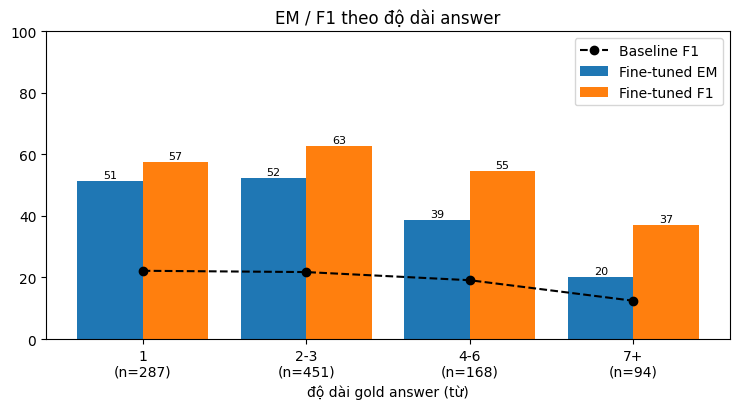

In [15]:
ft5 = tbl5[tbl5.Model == "Fine-tuned"].set_index("Answer length").loc[order]
bs5 = tbl5[tbl5.Model == "Baseline"].set_index("Answer length").loc[order]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(order))
ax.bar(x - .2, ft5["EM"], .4, label="Fine-tuned EM")
ax.bar(x + .2, ft5["F1"], .4, label="Fine-tuned F1")
ax.plot(x, bs5["F1"], "k--o", label="Baseline F1")
for i in range(len(order)):
    ax.text(x[i] - .2, ft5["EM"].iloc[i] + 1, f"{ft5['EM'].iloc[i]:.0f}", ha="center", fontsize=8)
    ax.text(x[i] + .2, ft5["F1"].iloc[i] + 1, f"{ft5['F1'].iloc[i]:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, [f"{b}\n(n={int(ft5['n'].iloc[i])})" for i, b in enumerate(order)])
ax.set_xlabel("độ dài gold answer (từ)")
ax.set_ylim(0, 100)
ax.set_title("EM / F1 theo độ dài answer")
ax.legend()
plt.tight_layout()
plt.savefig("answer_length_analysis.png", dpi=150)
plt.show()

## 8. Kiểm tra Prediction 3 và Prediction 4

In [16]:
rng = random.Random(0)
sub = test_ds.select(range(300))
others = [e["context"] for e in test_ds.select(range(300, 1000))]

def perturb(e, mode):
    sents = [e["context"][s:t] for s, t in qm._sentences(e["context"])]
    a_txt = e["answers"]["text"][0]
    a_idx = next(i for i, (s, t) in enumerate(qm._sentences(e["context"])) if s <= e["answers"]["answer_start"][0] < t)
    if mode == "shuffle":
        idx = list(range(len(sents)))
        rng.shuffle(idx)
        new = [sents[i] for i in idx]
        pos = idx.index(a_idx)
    else:  # distractor: chèn 3 câu từ đoạn văn khác vào trước câu chứa answer
        extra = [s_ for c in rng.sample(others, 3) for s_ in [c[s:t] for s, t in qm._sentences(c)][:1]]
        new = sents[:a_idx] + extra + sents[a_idx:]
        pos = a_idx + len(extra)
    ctx = " ".join(new)
    start = len(" ".join(new[:pos])) + (1 if pos > 0 else 0) + new[pos].find(a_txt) if a_txt in new[pos] else ctx.find(a_txt)
    return {"id": e["id"], "question": e["question"], "context": ctx,
            "answers": {"text": [a_txt] + e["answers"]["text"][1:], "answer_start": [start] + e["answers"]["answer_start"][1:]}}

from datasets import Dataset
res_pert = {}
for mode in ["original", "shuffle", "distractor"]:
    d = sub if mode == "original" else Dataset.from_list([perturb(e, mode) for e in sub])
    f = qm.build_features(d, tok384, 384, 128)
    s, e_ = qm.get_logits(model384, f)
    p = qm.postprocess(d, f, s, e_)
    res_pert[mode] = (qm.evaluate(d, {k: v["text"] for k, v in p.items()}), {k: v["text"] for k, v in p.items()})
tblp = pd.DataFrame([{"Context": k, "EM": v[0]["EM"], "F1": v[0]["F1"]} for k, v in res_pert.items()]).round(2)
changed = {m: sum(res_pert[m][1][i] != res_pert["original"][1][i] for i in res_pert[m][1]) for m in ["shuffle", "distractor"]}
print(tblp.to_string(index=False))
print("số câu đổi prediction so với original (300 câu):", changed)

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

   Context    EM    F1
  original 47.33 58.56
   shuffle 44.33 57.18
distractor 42.67 54.55
số câu đổi prediction so với original (300 câu): {'shuffle': 113, 'distractor': 113}


## 9. Wrong start vs wrong end (dữ liệu cho error_analysis.md)

In [17]:
PUNCT = " .,;:!?\"'()[]"

def strip_span(text, s, e):
    while s < e and text[s] in PUNCT: s += 1
    while e > s and text[e - 1] in PUNCT: e -= 1
    return s, e

rows = []
for ex, em, f1 in zip(test_ds, ft_res["em_list"], ft_res["f1_list"]):
    if em == 1:
        continue
    p = pred384[ex["id"]]
    golds = list(zip(ex["answers"]["text"], ex["answers"]["answer_start"]))
    gt, gs = max(golds, key=lambda g: qm.f1_score(p["text"], g[0]))
    gs, ge = strip_span(ex["context"], gs, gs + len(gt))
    ps, pe = strip_span(ex["context"], p["start_char"], p["end_char"])
    s_ok, e_ok = ps == gs, pe == ge
    ovl = min(pe, ge) > max(ps, gs)
    if s_ok and not e_ok:
        t = "wrong end"
    elif e_ok and not s_ok:
        t = "wrong start"
    elif s_ok and e_ok:
        t = "normalization only"
    elif ovl:
        t = "wrong boundary (both)"
    else:
        t = "wrong span (no overlap)"
    rows.append({"id": ex["id"], "type": t, "start_ok": s_ok, "end_ok": e_ok, "pred_longer": (pe - ps) > (ge - gs),
                 "question": ex["question"], "gold": gt, "prediction": p["text"], "F1": round(f1, 3),
                 "context_tokens": n_tokens(ex["question"], ex["context"]), "context": ex["context"]})
err = pd.DataFrame(rows)
err.to_csv("outputs/errors_fine_tuned.csv", index=False, encoding="utf-8")
print("Số câu EM = 0:", len(err))
print(err["type"].value_counts().to_string())
print("#wrong start (start sai, tính cả câu sai cả hai đầu):", (~err.start_ok).sum())
print("#wrong end   (end sai, tính cả câu sai cả hai đầu):", (~err.end_ok).sum())
ov = err[err.type != "wrong span (no overlap)"]
print("Trong các câu có overlap: prediction dài hơn gold:", ov.pred_longer.sum(), "| ngắn hơn hoặc lệch:", (~ov.pred_longer).sum())

Số câu EM = 0: 533
type
wrong span (no overlap)    341
wrong start                 83
wrong end                   79
wrong boundary (both)       30
#wrong start (start sai, tính cả câu sai cả hai đầu): 454
#wrong end   (end sai, tính cả câu sai cả hai đầu): 450
Trong các câu có overlap: prediction dài hơn gold: 115 | ngắn hơn hoặc lệch: 77


In [18]:
for t in ["wrong start", "wrong end", "wrong boundary (both)", "wrong span (no overlap)"]:
    print("=" * 10, t)
    print(err[err.type == t][["question", "gold", "prediction", "F1"]].head(8).to_string(index=False))

========== wrong start
                                                                             question                                     gold                                                                                 prediction    F1
                     At what address did Goldenson secure a new headquarters for ABC? 1330 Avenue of the Americas in Manhattan                      44 story building located at 1330 Avenue of the Americas in Manhattan 0.706
 When were Joseph Schumpeter and Norman Angell at their most prolific writing period?                       before World War I 1872–1967). While these non-Marxist writers were at their most prolific before World War I 0.444
                                    During what period did the Tower Theatre re-open?                               late 1970s                                                                                      1970s 0.667
What tool has measured the amount of dust that travels from the Sahara to the Ama

## 10. Lưu results.csv

In [19]:
rows = []
for L, (h_, m, p) in exp1.items():
    rows.append({"experiment": "exp1_context_length", "model": "distilbert-base-uncased", "setting": f"max_length={L},stride={m['stride']}",
                 "n": m["n_test"], "EM": m["EM"], "F1": m["F1"], "train_time_min": m["train_time_s"] / 60,
                 "train_loss": h_["train_loss"][-1], "val_loss": h_["val_loss"][-1]})
for _, r in tbl3.iterrows():
    rows.append({"experiment": "exp2_exp3_em_vs_f1", "model": r.Model, "setting": "test",
                 "n": len(test_ds), "EM": r.EM, "F1": r.F1,
                 "train_time_min": met384["train_time_s"] / 60 if "Fine" in r.Model else 0,
                 "train_loss": hist384["train_loss"][-1] if "Fine" in r.Model else None,
                 "val_loss": hist384["val_loss"][-1] if "Fine" in r.Model else None})
for _, r in tbl4.iterrows():
    rows.append({"experiment": "exp4_lexical_overlap", "model": r.Model, "setting": r.Group, "n": r.n, "EM": r.EM, "F1": r.F1})
for _, r in tbl5.iterrows():
    rows.append({"experiment": "exp5_answer_length", "model": r.Model, "setting": f"answer_len={r['Answer length']}", "n": r.n, "EM": r.EM, "F1": r.F1})
for _, r in tblp.iterrows():
    rows.append({"experiment": "prediction_3_4_perturbation", "model": "Fine-tuned DistilBERT", "setting": r.Context, "n": 300, "EM": r.EM, "F1": r.F1})
results = pd.DataFrame(rows).round(3)
results.to_csv("results.csv", index=False)
print(results.to_string(index=False))

                 experiment                      model                   setting    n    EM     F1  train_time_min  train_loss  val_loss
        exp1_context_length    distilbert-base-uncased  max_length=128,stride=42 1000 46.40 57.638          60.326       0.979     1.408
        exp1_context_length    distilbert-base-uncased  max_length=256,stride=85 1000 45.20 56.523          52.897       1.804     2.054
        exp1_context_length    distilbert-base-uncased max_length=384,stride=128 1000 46.70 57.500          70.484       1.757     2.015
         exp2_exp3_em_vs_f1 Baseline (keyword overlap)                      test 1000 11.20 20.560           0.000         NaN       NaN
         exp2_exp3_em_vs_f1      Fine-tuned DistilBERT                      test 1000 46.70 57.500          70.484       1.757     2.015
       exp4_lexical_overlap                   Baseline              high overlap  388 15.46 28.220             NaN         NaN       NaN
       exp4_lexical_overlap              